<a href="https://colab.research.google.com/github/guslimaa777/45419370/blob/main/aula11_metricas_classificacao_aluno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 11 – Métricas para classificação e análise em bases desbalanceadas

## Versão do aluno

### Objetivo da aula
Avaliar classificadores binários e interpretar corretamente as métricas, especialmente em uma base desbalanceada.

### Instruções
Complete as células indicadas ao longo da atividade e registre suas interpretações técnicas.  
Utilize também os gráficos para apoiar sua análise.


## 1. Importação das bibliotecas

Importe as bibliotecas necessárias para:
- leitura e manipulação da base;
- visualização;
- pré-processamento;
- treino de classificadores;
- cálculo das métricas de classificação.


In [77]:
# Importar a biblioteca pandas usando o apelido pd.
# O pandas será utilizado para trabalhar com tabelas e DataFrames.

# Importar a biblioteca numpy usando o apelido np.
# O numpy será utilizado para operações matemáticas e numéricas.

# Importar o módulo pyplot da biblioteca matplotlib usando o apelido plt.
# O pyplot será utilizado para criar gráficos.

# Importar a função train_test_split do módulo sklearn.model_selection.
# Essa função será utilizada para separar os dados em conjuntos de treinamento e teste.

# Importar ColumnTransformer do módulo sklearn.compose.
# Essa classe será utilizada para aplicar diferentes tratamentos a diferentes colunas dos dados.

# Importar Pipeline do módulo sklearn.pipeline.
# Essa classe será utilizada para organizar várias etapas de pré-processamento e modelagem em uma sequência.

# Importar OneHotEncoder e StandardScaler do módulo sklearn.preprocessing.
# OneHotEncoder será utilizado para transformar variáveis categóricas em valores numéricos.
# StandardScaler será utilizado para padronizar variáveis numéricas.

# Importar SimpleImputer do módulo sklearn.impute.
# SimpleImputer será utilizado para tratar valores ausentes nos dados.

# Importar LogisticRegression do módulo sklearn.linear_model.
# LogisticRegression será utilizado para criar o modelo de classificação por Regressão Logística.

# Importar DecisionTreeClassifier do módulo sklearn.tree.
# DecisionTreeClassifier será utilizado para criar o modelo de classificação por Árvore de Decisão.

# Importar as métricas confusion_matrix e ConfusionMatrixDisplay do módulo sklearn.metrics.
# confusion_matrix será utilizada para criar a matriz de confusão.
# ConfusionMatrixDisplay será utilizada para exibir a matriz de confusão graficamente.

# Importar accuracy_score, precision_score, recall_score e f1_score do módulo sklearn.metrics.
# accuracy_score será utilizada para calcular a acurácia.
# precision_score será utilizada para calcular a precisão.
# recall_score será utilizada para calcular o recall.
# f1_score será utilizada para calcular o F1-Score.

# Importar roc_curve e roc_auc_score do módulo sklearn.metrics.
# roc_curve será utilizada para calcular os valores necessários para construir a curva ROC.
# roc_auc_score será utilizada para calcular a área sob a curva ROC (AUC).

In [78]:
# Complete aqui
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score
)

## 2. Leitura da base

Leia o arquivo `dados_aula11_classificacao_desbalanceada.csv` e exiba as primeiras linhas.


In [79]:
# Complete aqui
df = pd.read_csv('dados_aula11_classificacao_desbalanceada.csv')
df.head()

,id_registro,linha,turno,produto,temperatura_c,pressao_bar,vibracao_mm_s,abertura_valvula_pct,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,horas_operacao_bomba,falha_operacional
0,CLS_0001,Linha_C,Noite,Acido,32.33,4.54,2.40,72.08,20.05,1.41,4.32,3,572.9,0
1,CLS_0002,Linha_C,Manhã,Acido,47.27,4.51,2.56,48.98,18.24,NaN,4.74,4,402.0,1
2,CLS_0003,Linha_C,Manhã,Base,49.44,3.44,1.26,55.33,20.46,NaN,3.91,2,275.4,0
3,CLS_0004,Linha_C,Tarde,NaN,50.92,3.68,2.03,63.97,15.69,2.09,1.35,2,374.0,0
4,CLS_0005,Linha_B,Manhã,Base,60.52,3.68,2.61,64.77,18.79,1.04,2.45,1,477.5,0


## 3. Inspeção inicial da base

Verifique:
- dimensão da base;
- tipos de dados;
- valores faltantes;
- duplicatas;
- distribuição da variável-alvo.


In [80]:
# Exibir a dimensão da base de dados usando df.shape.
# df.shape retorna a quantidade de linhas e de colunas da base.
# O texto 'Dimensão da base:' será exibido antes do resultado.

# Exibir uma mensagem indicando que serão apresentados os tipos de dados.
# Usar \n antes do texto para começar a exibição em uma nova linha.

# Exibir os tipos de dados de todas as colunas usando df.dtypes.
# df.dtypes informa o tipo de dado armazenado em cada coluna.

# Exibir uma mensagem indicando que serão apresentados os valores faltantes.
# Usar \n para iniciar a exibição em uma nova linha.

# Verificar a quantidade de valores faltantes em cada coluna usando df.isna().sum().
# df.isna() identifica os valores ausentes.
# .sum() conta quantos valores ausentes existem em cada coluna.

# Exibir a quantidade de registros duplicados usando df.duplicated().sum().
# df.duplicated() identifica as linhas duplicadas.
# .sum() conta quantas linhas duplicadas existem na base.

# Exibir uma mensagem indicando que será apresentada a distribuição da variável-alvo.
# A variável-alvo utilizada neste exercício é a coluna 'falha_operacional'.

# Exibir a distribuição da variável-alvo usando df['falha_operacional'].value_counts().
# df['falha_operacional'] seleciona a coluna que contém a variável-alvo.
# .value_counts() conta quantas vezes cada classe aparece nessa coluna.
# O resultado permite verificar a quantidade de registros de cada classe da variável-alvo.

In [81]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicatas:',df.duplicated().sum())
print('\nDistribuição da variável-alvo:')
print(df['falha_operacional'].value_counts())

Dimensão da base: (430, 14)

Tipos de dados:
id_registro              object
linha                    object
turno                    object
produto                  object
temperatura_c           float64
pressao_bar             float64
vibracao_mm_s           float64
abertura_valvula_pct    float64
consumo_energia_kwh     float64
tempo_resposta_s        float64
erro_vazao_pct          float64
leituras_invalidas        int64
horas_operacao_bomba    float64
falha_operacional         int64
dtype: object

Valores faltantes:
id_registro             0
linha                   0
turno                   0
produto                 8
temperatura_c           8
pressao_bar             8
vibracao_mm_s           0
abertura_valvula_pct    0
consumo_energia_kwh     0
tempo_resposta_s        8
erro_vazao_pct          0
leituras_invalidas      0
horas_operacao_bomba    0
falha_operacional       0
dtype: int64

Duplicatas: 10

Distribuição da variável-alvo:
falha_operacional
0    371
1     59
Name: count,

**Registro do aluno:**  
-  
-  
-  


## 4. Visualização do desbalanceamento

Calcule a distribuição da variável-alvo e crie um gráfico de barras.


In [82]:
# Criar uma variável chamada dist para armazenar a distribuição da variável-alvo.
# Selecionar a coluna 'falha_operacional' usando df['falha_operacional'].
# Contar a quantidade de registros de cada classe usando o método .value_counts().
# Usar .sort_index() para ordenar as classes pelo índice, colocando a classe 0 antes da classe 1.

# Alterar os nomes dos índices de dist para facilitar a interpretação dos resultados.
# A primeira posição corresponde à classe 0 e deve receber o texto 'Sem falha (0)'.
# A segunda posição corresponde à classe 1 e deve receber o texto 'Falha (1)'.

# Exibir a variável dist para visualizar a quantidade de registros em cada classe.

In [83]:
# Complete aqui
dist = df['falha_operacional'].value_counts().sort_index()
dist.index = ['Sem falha (0)', 'Falha (1)']
dist

,count
Sem falha (0),371
Falha (1),59


In [84]:
# Criar uma nova figura para o gráfico usando plt.figure().
# Usar figsize=(7,4) para definir o tamanho da figura:
# 7 unidades de largura e 4 unidades de altura.

# Criar um gráfico de barras usando plt.bar().
# Usar dist.index no eixo X para representar as categorias:
# 'Sem falha (0)' e 'Falha (1)'.
# Usar dist.values no eixo Y para representar a quantidade de registros.

# Definir o título do gráfico usando plt.title().
# O título deve ser 'Distribuição da variável-alvo'.

# Definir o nome do eixo Y usando plt.ylabel().
# O texto do eixo Y deve ser 'Quantidade de registros'.

# Ajustar automaticamente o espaçamento dos elementos da figura usando plt.tight_layout().
# Esse comando ajuda a evitar que títulos e textos fiquem cortados.

# Exibir o gráfico na tela usando plt.show().

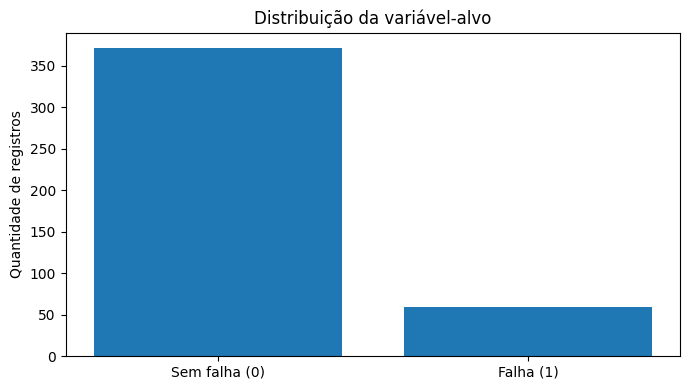

In [85]:
# Gere o gráfico aqui
plt.figure(figsize=(7,4))
plt.bar(dist.index, dist.values)
plt.title('Distribuição da variável-alvo')
plt.ylabel('Quantidade de registros')
plt.tight_layout()
plt.show()

## 5. Limpeza básica

Remova as duplicatas da base.


In [86]:
# Remover as linhas duplicadas do DataFrame usando o método .drop_duplicates().
# Usar .copy() para criar uma cópia independente do DataFrame após a remoção.
# Armazenar o resultado novamente na variável df.

# Exibir a nova dimensão da base usando df.shape.
# O resultado mostrará a quantidade de linhas e colunas após a remoção das duplicatas.
# Usar o texto 'Dimensão após remoção de duplicatas:' antes do resultado.

In [87]:
# Complete aqui
df = df.drop_duplicates().copy()
print('Dimensão após remoção de duplicatas:', df.shape)

Dimensão após remoção de duplicatas: (420, 14)


## 6. Definição de X e y

Separe:
- `X`: variáveis de entrada;
- `y`: variável-alvo `falha_operacional`.

**Pergunta:**  
Por que `id_registro` não deve ser usado como variável preditora?


In [88]:
# Criar a variável X contendo as características (variáveis explicativas) que serão usadas pelo modelo.
# Usar o método .drop() para remover colunas que não devem ser utilizadas como características.
# Remover a coluna 'id_registro', pois ela é apenas um identificador do registro.
# Remover a coluna 'falha_operacional', pois ela é a variável-alvo que queremos prever.
# Usar o parâmetro columns=['id_registro', 'falha_operacional'] para indicar as duas colunas que serão removidas.

# Criar a variável y contendo a variável-alvo do modelo.
# Selecionar a coluna 'falha_operacional' do DataFrame usando df['falha_operacional'].
# A variável y armazenará a resposta que o modelo deverá aprender a prever.

# Exibir a dimensão de X usando X.shape.
# X.shape mostrará a quantidade de registros e a quantidade de características utilizadas pelo modelo.

# Exibir a dimensão de y usando y.shape.
# y.shape mostrará a quantidade de valores existentes na variável-alvo.

In [89]:
# Complete aqui
X = df.drop(columns=['id_registro', 'falha_operacional'])
y = df['falha_operacional']

print(X.shape)
print(y.shape)

(420, 12)
(420,)


**Resposta do aluno:**  


## 7. Divisão em treino e teste

Faça a divisão com `stratify=y`.


In [90]:
# Dividir os dados X e y em dois conjuntos: treinamento e teste.
# Usar a função train_test_split() para realizar essa divisão.
# Informar X e y como os dados que serão divididos.

# Usar test_size=0.25 para reservar 25% dos dados para o conjunto de teste.
# Os 75% restantes serão utilizados para o treinamento do modelo.

# Usar random_state=42 para garantir que a divisão seja sempre reproduzível.
# Isso significa que, ao executar novamente o código, os mesmos registros serão
# selecionados para treino e teste.

# Usar stratify=y para manter no treino e no teste uma proporção de classes
# semelhante à existente na variável-alvo y.
# Isso é importante porque estamos trabalhando com um problema de classificação.

# Armazenar os quatro resultados da divisão:
# X_train → características utilizadas no treinamento.
# X_test  → características utilizadas no teste.
# y_train → classes reais correspondentes aos dados de treinamento.
# y_test  → classes reais correspondentes aos dados de teste.

# Exibir a dimensão dos dados de treinamento usando .shape.
# Mostrar X_train.shape para verificar linhas e características do treino.
# Mostrar y_train.shape para verificar a quantidade de classes do treino.

# Exibir a dimensão dos dados de teste usando .shape.
# Mostrar X_test.shape para verificar linhas e características do teste.
# Mostrar y_test.shape para verificar a quantidade de classes do teste.

# Exibir uma mensagem indicando que será analisada a distribuição das classes em y_train.
# Usar \n para iniciar a mensagem em uma nova linha.

# Contar a quantidade de registros de cada classe em y_train usando .value_counts().
# Isso permite verificar quantos registros pertencem à classe 0 e quantos pertencem à classe 1.

# Exibir uma mensagem indicando que será analisada a distribuição das classes em y_test.
# Usar \n para iniciar a mensagem em uma nova linha.

# Contar a quantidade de registros de cada classe em y_test usando .value_counts().
# Isso permite verificar quantos registros pertencem à classe 0 e quantos pertencem à classe 1.

In [91]:
# Garante que X e y utilizem a base limpa atualizada (com 420 linhas)
X = df.drop(columns=['id_registro', 'falha_operacional'])
y = df['falha_operacional']

# Divisão estratificada de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print('Treino:', X_train.shape,  y_train.shape)
print('Teste:', X_test.shape, y_test.shape)
print('\nDistribuição em y_train:')
print(y_train.value_counts())
print('\nDistribuição em y_test:')
print(y_test.value_counts())

Treino: (315, 12) (315,)
Teste: (105, 12) (105,)

Distribuição em y_train:
falha_operacional
0    271
1     44
Name: count, dtype: int64

Distribuição em y_test:
falha_operacional
0    90
1    15
Name: count, dtype: int64


**Pergunta:**  
Por que o uso de `stratify=y` é importante nesta aula?


**Resposta do aluno:**  


## 8. Pré-processamento com pipeline

Monte um pipeline com:
- imputação da mediana + padronização para numéricas;
- imputação da moda + one-hot encoding para categóricas.


In [92]:
# Identificar as colunas numéricas de X usando o método .select_dtypes().
# Usar include=['int64', 'float64'] para selecionar colunas que possuem números inteiros
# ou números decimais.
# Usar .columns para obter os nomes dessas colunas.
# Usar .tolist() para transformar os nomes das colunas em uma lista.
# Armazenar essa lista na variável colunas_numericas.

# Identificar as colunas categóricas de X usando o método .select_dtypes().
# Usar include=['object'] para selecionar colunas que armazenam textos/categorias.
# Usar .columns para obter os nomes dessas colunas.
# Usar .tolist() para transformar os nomes das colunas em uma lista.
# Armazenar essa lista na variável colunas_categoricas.

# Criar um pipeline chamado transformador_numerico usando Pipeline(steps=[...]).
# Esse pipeline terá duas etapas para tratar as colunas numéricas.

# Na primeira etapa, usar SimpleImputer(strategy='median') com o nome 'imputer'.
# Essa etapa preencherá valores ausentes das colunas numéricas usando a mediana de cada coluna.

# Na segunda etapa, usar StandardScaler() com o nome 'scaler'.
# Essa etapa padronizará os valores das colunas numéricas.

# Criar um pipeline chamado transformador_categorico usando Pipeline(steps=[...]).
# Esse pipeline terá duas etapas para tratar as colunas categóricas.

# Na primeira etapa, usar SimpleImputer(strategy='most_frequent') com o nome 'imputer'.
# Essa etapa preencherá valores ausentes usando o valor mais frequente de cada coluna.

# Na segunda etapa, usar OneHotEncoder(handle_unknown='ignore') com o nome 'onehot'.
# Essa etapa transformará as categorias de texto em colunas numéricas.
# Usar handle_unknown='ignore' para evitar erro caso apareça uma categoria nova
# nos dados de teste que não estava presente nos dados de treinamento.

# Criar o objeto preprocessador usando ColumnTransformer(transformers=[...]).
# O ColumnTransformer permitirá aplicar o tratamento numérico e categórico
# separadamente às suas respectivas colunas.

# Criar a primeira transformação com o nome 'num'.
# Usar transformador_numerico como o pipeline que será aplicado.
# Usar colunas_numericas para indicar quais colunas receberão esse tratamento.

# Criar a segunda transformação com o nome 'cat'.
# Usar transformador_categorico como o pipeline que será aplicado.
# Usar colunas_categoricas para indicar quais colunas receberão esse tratamento.

# Exibir as listas colunas_numericas e colunas_categoricas.
# Isso permite conferir quais colunas foram identificadas como numéricas
# e quais foram identificadas como categóricas.

In [93]:
# Complete aqui

# Separar os dados em treino e teste
X_treino, X_teste = train_test_split(
    X, test_size=0.2, random_state=42
)

# Identificar colunas numéricas e categóricas
colunas_numericas = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

colunas_categoricas = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Transformador numérico
transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Transformador categórico
transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Preprocessador
preprocessador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, colunas_numericas),
    ('cat', transformador_categorico, colunas_categoricas)
])

# Treinar o preprocessador e transformar os dados
X_treinado = preprocessador.fit_transform(X_treino)
X_teste_transformado = preprocessador.transform(X_teste)

print("Treino:", X_treinado.shape)
print("Teste:", X_teste_transformado.shape)

Treino: (336, 18)
Teste: (84, 18)


## 9. Criação de dois classificadores

Crie:
- um modelo de Regressão Logística;
- um modelo de Árvore de Decisão Classificadora.

### Observação
Como o problema é de **classificação binária**, as métricas mais adequadas são métricas de classificação, como acurácia, precisão, recall, F1-score, especificidade e AUC.


In [94]:
# Criar um pipeline chamado modelo_logistico usando Pipeline(steps=[...]).
# O pipeline terá duas etapas: o pré-processamento dos dados e o modelo de classificação.

# Na primeira etapa, usar o nome 'preprocessador' e o objeto preprocessador.
# Essa etapa aplicará automaticamente o tratamento das colunas numéricas e categóricas
# definido anteriormente no ColumnTransformer.

# Na segunda etapa, usar o nome 'modelo' e criar um LogisticRegression().
# Usar max_iter=1000 para permitir até 1000 iterações durante o treinamento
# da Regressão Logística.

# Criar um segundo pipeline chamado modelo_arvore usando Pipeline(steps=[...]).
# Esse pipeline também terá duas etapas: pré-processamento e modelo de classificação.

# Na primeira etapa, usar o nome 'preprocessador' e o objeto preprocessador.
# O mesmo pré-processamento será aplicado antes da Árvore de Decisão.

# Na segunda etapa, usar o nome 'modelo' e criar um DecisionTreeClassifier().
# Usar max_depth=5 para limitar a profundidade máxima da árvore a 5 níveis.
# Usar random_state=42 para tornar o resultado reproduzível.

In [95]:
# Complete aqui
modelo_logistico = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', LogisticRegression(max_iter=1000))
])

modelo_arvore = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', DecisionTreeClassifier(max_depth=5, random_state=42))
])

## 10. Treino dos modelos

Treine os dois classificadores.


In [96]:
# Treinar o modelo de Regressão Logística usando o método .fit().
# Usar X_train como os dados de entrada para o treinamento.
# Usar y_train como os valores reais das classes que o modelo deverá aprender.
# O método .fit() executará automaticamente o pré-processamento definido no pipeline
# e depois treinará o modelo de Regressão Logística.

# Treinar o modelo de Árvore de Decisão usando o método .fit().
# Usar X_train como os dados de entrada para o treinamento.
# Usar y_train como os valores reais das classes que o modelo deverá aprender.
# O método .fit() executará automaticamente o pré-processamento definido no pipeline
# e depois treinará o modelo de Árvore de Decisão.

# Exibir a mensagem 'Modelos treinados com sucesso.' para confirmar
# que o treinamento dos dois modelos foi concluído.

In [97]:
# Treinando os modelos com os dados de treino estratificados corretos
modelo_logistico.fit(X_train, y_train)
modelo_arvore.fit(X_train, y_train)

print('Modelos treinados com sucesso.')

Modelos treinados com sucesso.


## 11. Predições e probabilidades

Gere:
- as classes previstas;
- as probabilidades da classe positiva.


In [98]:
# Fazer as previsões do modelo de Regressão Logística usando o método .predict().
# Usar X_test como os dados que serão classificados pelo modelo.
# Armazenar as classes previstas na variável pred_log.

# Fazer as previsões do modelo de Árvore de Decisão usando o método .predict().
# Usar X_test como os dados que serão classificados pelo modelo.
# Armazenar as classes previstas na variável pred_tree.

# Calcular as probabilidades previstas pelo modelo de Regressão Logística
# usando o método .predict_proba().
# Usar X_test como os dados para os quais as probabilidades serão calculadas.
# Usar [:, 1] para selecionar todas as linhas e somente a coluna de índice 1.
# A coluna 1 representa a probabilidade de pertencer à classe 1.
# Armazenar essas probabilidades na variável proba_log.

# Calcular as probabilidades previstas pelo modelo de Árvore de Decisão
# usando o método .predict_proba().
# Usar X_test como os dados para os quais as probabilidades serão calculadas.
# Usar [:, 1] para selecionar todas as linhas e somente a coluna de índice 1.
# A coluna 1 representa a probabilidade de pertencer à classe 1.
# Armazenar essas probabilidades na variável proba_tree.

In [99]:
# Gerando as classes previstas para o conjunto de teste
pred_log = modelo_logistico.predict(X_test)
pred_tree = modelo_arvore.predict(X_test)

# Gerando as probabilidades da classe positiva (Falha - 1)
proba_log = modelo_logistico.predict_proba(X_test)[:, 1]
proba_tree = modelo_arvore.predict_proba(X_test)[:, 1]

print('Previsões e probabilidades calculadas com sucesso.')

Previsões e probabilidades calculadas com sucesso.


## 12. Matriz de confusão

Calcule a matriz de confusão dos dois modelos e gere a visualização.


In [100]:
# Criar a matriz de confusão do modelo de Regressão Logística.
# Usar a função confusion_matrix().
# Informar y_test como os valores reais das classes.
# Informar pred_log como as classes previstas pelo modelo de Regressão Logística.
# Armazenar o resultado na variável cm_log.

# Criar a matriz de confusão do modelo de Árvore de Decisão.
# Usar a função confusion_matrix().
# Informar y_test como os valores reais das classes.
# Informar pred_tree como as classes previstas pelo modelo de Árvore de Decisão.
# Armazenar o resultado na variável cm_tree.

# Exibir o texto 'Matriz de confusão - Regressão Logística'
# para identificar a matriz que será apresentada.

# Exibir a matriz de confusão armazenada na variável cm_log.

# Exibir uma mensagem indicando a matriz de confusão da Árvore de Decisão.
# Usar \n para iniciar a mensagem em uma nova linha.

# Exibir a matriz de confusão armazenada na variável cm_tree.

In [101]:
# Calculando a matriz de confusão para os dois modelos
cm_log = confusion_matrix(y_test, pred_log)
cm_tree = confusion_matrix(y_test, pred_tree)

print('Matriz de confusão - Regressão Logística')
print(cm_log)
print('\nMatriz de confusão - Árvore de Decisão')
print(cm_tree)

Matriz de confusão - Regressão Logística
[[85  5]
 [ 7  8]]

Matriz de confusão - Árvore de Decisão
[[83  7]
 [ 8  7]]


In [102]:
# Criar uma figura contendo dois gráficos lado a lado usando plt.subplots().
# Usar 1 linha e 2 colunas com os parâmetros 1 e 2.
# Usar figsize=(10,4) para definir o tamanho total da figura.
# Armazenar a figura na variável fig e os dois eixos na variável axes.

# Criar a visualização da matriz de confusão da Regressão Logística.
# Usar ConfusionMatrixDisplay(cm_log) para utilizar a matriz armazenada em cm_log.
# Usar o método .plot() para desenhar a matriz.
# Usar ax=axes[0] para colocar o gráfico no primeiro eixo.
# Usar colorbar=False para não exibir a barra de cores ao lado da matriz.

# Definir o título do primeiro gráfico usando axes[0].set_title().
# Usar o título 'Regressão Logística'.

# Criar a visualização da matriz de confusão da Árvore de Decisão.
# Usar ConfusionMatrixDisplay(cm_tree) para utilizar a matriz armazenada em cm_tree.
# Usar o método .plot() para desenhar a matriz.
# Usar ax=axes[1] para colocar o gráfico no segundo eixo.
# Usar colorbar=False para não exibir a barra de cores ao lado da matriz.

# Definir o título do segundo gráfico usando axes[1].set_title().
# Usar o título 'Árvore de Decisão'.

# Ajustar automaticamente o espaçamento entre os elementos da figura
# usando plt.tight_layout().

# Exibir os dois gráficos na tela usando plt.show().

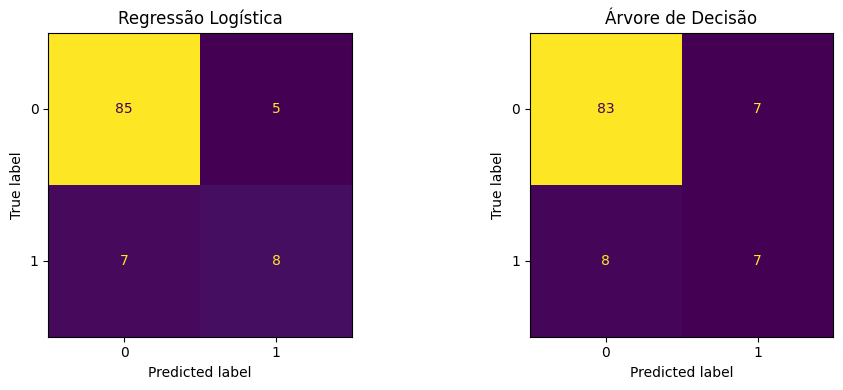

In [103]:
# Gere a visualização aqui
fig, axes = plt.subplots(1, 2, figsize=(10,4))

ConfusionMatrixDisplay(cm_log).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Regressão Logística')

ConfusionMatrixDisplay(cm_tree).plot(ax=axes[1], colorbar=False)
axes[1].set_title('Árvore de Decisão')

plt.tight_layout()
plt.show()

## 13. Cálculo das métricas

Calcule:
- Acurácia
- Precisão
- Recall
- F1-score
- Especificidade
- AUC

### Interpretação resumida
- **Acurácia**: proporção total de acertos;
- **Precisão**: entre os casos previstos como falha, quantos realmente eram falha;
- **Recall**: entre as falhas reais, quantas o modelo conseguiu detectar;
- **F1-score**: equilíbrio entre precisão e recall; “O modelo consegue encontrar os casos positivos e, ao mesmo tempo, evitar muitas previsões positivas erradas?”
- **Especificidade**: capacidade de reconhecer corretamente os casos sem falha;
- **AUC**: capacidade de separação entre classes em diferentes limiares.


In [104]:
# Criar uma função chamada especificidade() para calcular a especificidade do modelo.
# A função receberá dois parâmetros:
# y_real → valores reais das classes.
# y_pred → valores previstos pelo modelo.

# Criar a matriz de confusão usando confusion_matrix(y_real, y_pred).
# Usar .ravel() para transformar os quatro valores da matriz em quatro variáveis.
# Armazenar os valores nas variáveis:
# tn → Verdadeiros Negativos (True Negative).
# fp → Falsos Positivos (False Positive).
# fn → Falsos Negativos (False Negative).
# tp → Verdadeiros Positivos (True Positive).

# Retornar a especificidade usando a fórmula tn / (tn + fp).
# A especificidade mede a capacidade do modelo de identificar corretamente
# os registros que pertencem à classe negativa (classe 0).

# Criar um DataFrame chamado metricas usando pd.DataFrame().
# O DataFrame armazenará as métricas dos dois modelos:
# Regressão Logística e Árvore de Decisão.

# Criar a coluna 'Modelo'.
# Inserir os nomes 'Regressão Logística' e 'Árvore de Decisão'.

# Criar a coluna 'Acurácia'.
# Calcular a acurácia da Regressão Logística usando accuracy_score(y_test, pred_log).
# Calcular a acurácia da Árvore de Decisão usando accuracy_score(y_test, pred_tree).
# Usar y_test como os valores reais e pred_log/pred_tree como as previsões.

# Criar a coluna 'Precisão'.
# Calcular a precisão da Regressão Logística usando precision_score(y_test, pred_log, zero_division=0).
# Calcular a precisão da Árvore de Decisão usando precision_score(y_test, pred_tree, zero_division=0).
# Usar zero_division=0 para retornar 0 caso não seja possível calcular a precisão.

# Criar a coluna 'Recall'.
# Calcular o recall da Regressão Logística usando recall_score(y_test, pred_log, zero_division=0).
# Calcular o recall da Árvore de Decisão usando recall_score(y_test, pred_tree, zero_division=0).
# Usar zero_division=0 para evitar erro quando não houver casos positivos previstos.

# Criar a coluna 'F1-score'.
# Calcular o F1-score da Regressão Logística usando f1_score(y_test, pred_log, zero_division=0).
# Calcular o F1-score da Árvore de Decisão usando f1_score(y_test, pred_tree, zero_division=0).
# Usar zero_division=0 para evitar erro quando não houver casos positivos previstos.

# Criar a coluna 'Especificidade'.
# Calcular a especificidade da Regressão Logística chamando especificidade(y_test, pred_log).
# Calcular a especificidade da Árvore de Decisão chamando especificidade(y_test, pred_tree).

# Criar a coluna 'AUC'.
# Calcular a AUC da Regressão Logística usando roc_auc_score(y_test, proba_log).
# Usar proba_log, que contém as probabilidades previstas para a classe 1.
# Calcular a AUC da Árvore de Decisão usando roc_auc_score(y_test, proba_tree).
# Usar proba_tree, que contém as probabilidades previstas para a classe 1.

# Usar o método .round(4) no DataFrame de métricas.
# Arredondar todas as métricas numéricas para 4 casas decimais.

# Exibir a variável metricas para visualizar a tabela final de comparação
# entre a Regressão Logística e a Árvore de Decisão.

In [105]:
# Complete aqui
def especificidade(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    return tn / (tn + fp)

metricas = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Árvore de Decisão'],
    'Acurácia': [
        accuracy_score(y_test, pred_log),
        accuracy_score(y_test, pred_tree)
    ],
    'Precisão': [
        precision_score(y_test, pred_log, zero_division=0),
        precision_score(y_test, pred_tree, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, pred_log, zero_division=0),
        recall_score(y_test, pred_tree, zero_division=0)
    ],
    'F1-score': [
        f1_score(y_test, pred_log, zero_division=0),
        f1_score(y_test, pred_tree, zero_division=0)
    ],
    'Especificidade': [
        especificidade(y_test, pred_log),
        especificidade(y_test, pred_tree)
    ],
    'AUC': [
        roc_auc_score(y_test, proba_log),
        roc_auc_score(y_test, proba_tree)
    ]
}).round(4)

metricas

,Modelo,Acurácia,Precisão,Recall,F1-score,Especificidade,AUC
0,Regressão Logística,0.8857,0.6154,0.5333,0.5714,0.9444,0.9170
1,Árvore de Decisão,0.8571,0.5000,0.4667,0.4828,0.9222,0.7874


###***Precisão***
>Quando o modelo disse "Falha", quantas vezes realmente era falha?


|            | Previsto 0 | Previsto 1 |
| ---------- | ---------: | ---------: |
| **Real 0** |         85 |          5 |
| **Real 1** |          7 |          8 |

>Para a classe 1 (Falha):
* TN = 85
* FP = 5
* FN = 7
* TP = 8


#### ***Fórmula da Precisão***
> $$
Precisão = \frac{TP}{TP + FP}
$$

###***Recall***
>De todas as falhas que realmente aconteceram, quantas o modelo conseguiu encontrar?

#### ***Fórmula do Recall***

> $$
Precisão = \frac{TP}{TP + FN}
$$


###***F1-Score***

>Qual é o equilíbrio entre Precisão e Recall?<br/>
`“O modelo consegue encontrar os casos positivos e, ao mesmo tempo, evitar muitas previsões positivas erradas?”`

$$
F1 = 2 \times \frac{Precisão \times Recall}{Precisão + Recall}
$$

$$
F1 = 2 \times \frac{0,6154 \times 0,5333}{0,6154 + 0,5333}
= 0,5714
$$

###***Especificidade***

>Dos casos sem falha, quantos identifiquei corretamente?

$$
Especificidade = \frac{TN}{TN + FP}
$$

$$
Especificidade = \frac{85}{85 + 5}
= 0,9444
$$

###***AUC(Area Under Cuve)***

>Quão bem o modelo separa falha de sem falha?

$$
AUC = 0,9170
$$

A AUC mede a capacidade do modelo de separar as classes
"Falha" e "Sem falha" considerando diferentes pontos de corte.


* TPR = (True Positive Rate) - Taxa de Verdadeiros Positivos = Recall
* FPR = (False Positive Rate) - Taxa de Falsos Positivos
* A integral calcula a área abaixo da curva ROC.

$$
AUC = \int_0^1 TPR(FPR)\,d(FPR)
$$

Onde:

$$
TPR = \frac{TP}{TP + FN}
$$

$$
FPR = \frac{FP}{FP + TN}
$$


>Exemplo:

* AUC = 0,50 → modelo praticamente não diferencia as classes.
* AUC = 0,80 → modelo consegue fazer uma boa separação.
* AUC = 1,00 → separação perfeita.

> Resumindo: ***`A AUC é a área sob a curva ROC, calculada enquanto o FPR varia de 0 até 1, considerando o valor correspondente de TPR.`***


## 14. Visualização comparativa das métricas

Crie gráficos comparando os dois classificadores.


In [106]:
# Complete aqui
metricas_plot = metricas.set_index('Modelo')

In [107]:
# Percorrer cada uma das métricas que serão comparadas nos gráficos.
# Usar uma lista contendo os nomes das colunas:
# 'Acurácia', 'Precisão', 'Recall', 'F1-score', 'Especificidade' e 'AUC'.
# Armazenar temporariamente o nome da métrica na variável coluna.

# Criar uma nova figura para cada métrica usando plt.figure().
# Usar figsize=(7,4) para definir 7 unidades de largura e 4 de altura.

# Criar um gráfico de barras usando plt.bar().
# Usar metricas_plot.index no eixo X para representar os modelos.
# Usar metricas_plot[coluna] no eixo Y para representar os valores
# da métrica que está sendo analisada no momento.

# Definir o título do gráfico usando plt.title().
# Usar uma f-string para incluir automaticamente o nome da métrica.
# O título terá o formato 'Comparação de [nome da métrica]'.

# Definir o limite do eixo Y usando plt.ylim(0, 1.05).
# O eixo Y começará em 0 e terminará em 1.05.
# Isso permite visualizar claramente métricas que variam entre 0 e 1.

# Definir o nome do eixo Y usando plt.ylabel().
# Usar a variável coluna para mostrar o nome da métrica no eixo Y.

# Ajustar automaticamente o espaçamento dos elementos do gráfico
# usando plt.tight_layout().

# Exibir o gráfico na tela usando plt.show().
# Como plt.show() está dentro do for, será exibido um gráfico separado para cada métrica.

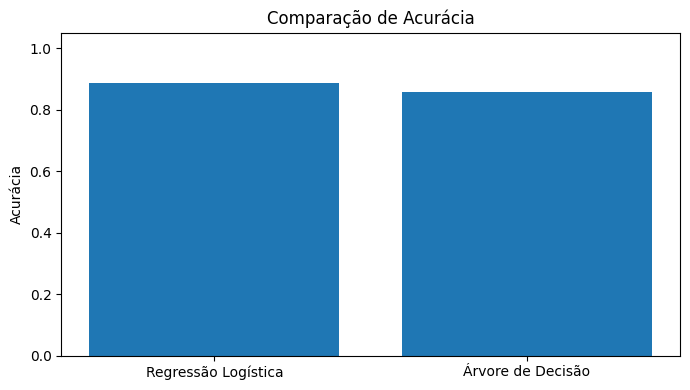

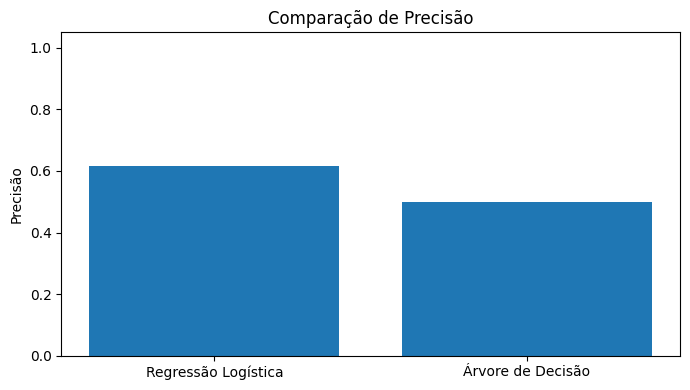

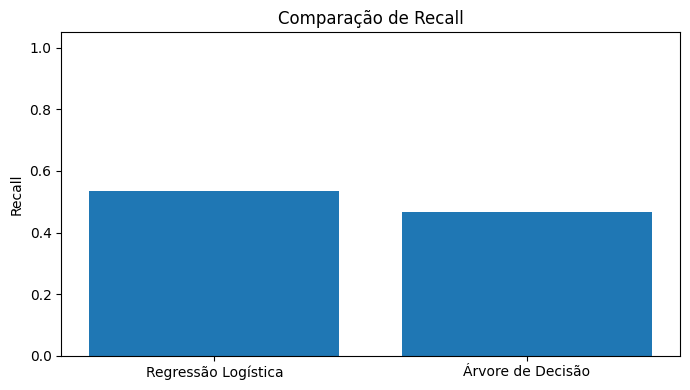

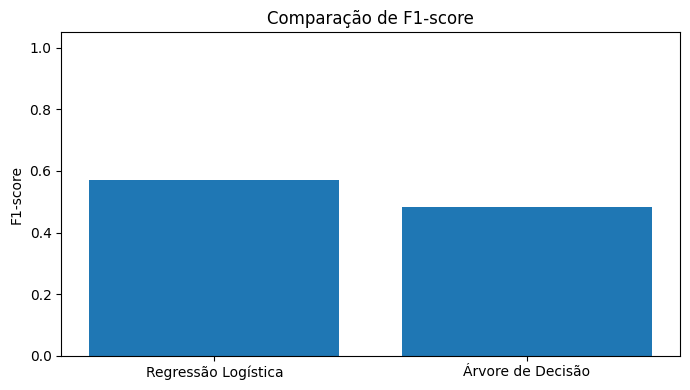

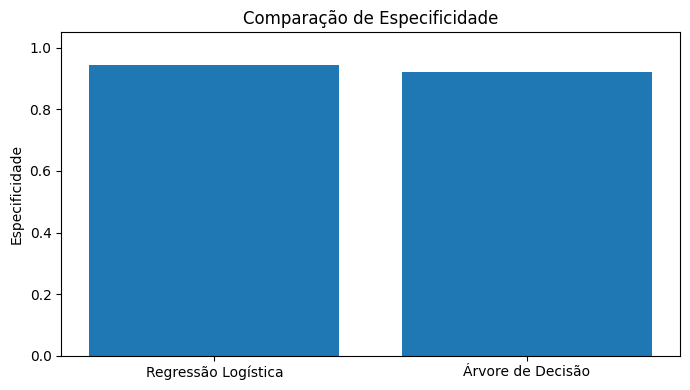

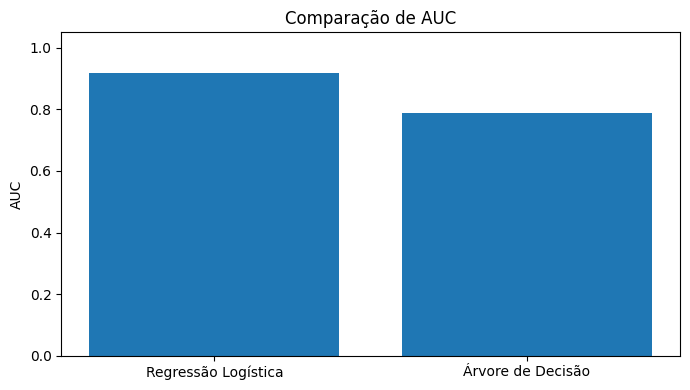

In [108]:
# Gere os gráficos aqui para Acurácia, Precisão, Recall, F1-score, Especificidade e AUC
for coluna in ['Acurácia', 'Precisão', 'Recall', 'F1-score', 'Especificidade', 'AUC']:
    plt.figure(figsize=(7,4))
    plt.bar(metricas_plot.index, metricas_plot[coluna])
    plt.title(f'Comparação de {coluna}')
    plt.ylim(0, 1.05)
    plt.ylabel(coluna)
    plt.tight_layout()
    plt.show()

## 15. Curva ROC

***ROC = Receiver Operating Characteristic (Característica de Operação do Receptor)***


A curva ROC mostra o comportamento do classificador em diferentes limiares de decisão.  
O valor de **AUC** resume essa curva em um único número.

### Referência geral
- AUC próxima de 0,5: separação fraca
- AUC entre 0,7 e 0,8: razoável
- AUC entre 0,8 e 0,9: boa
- AUC acima de 0,9: muito boa

<br/>

* A Função ROC testa diferentes thresholds automaticamente para construir a curva
* Threshold é o ponto de corte usado para transformar uma probabilidade em uma decisão ***(Falha/Sem Falha)***

In [109]:
# Calcular os pontos da curva ROC da Regressão Logística usando roc_curve().
# Usar y_test como os valores reais das classes.
# Usar proba_log como as probabilidades previstas para a classe 1.
# A função roc_curve() retorna três valores:
# FPR → taxa de falsos positivos.
# TPR → taxa de verdadeiros positivos.
# thresholds → diferentes pontos de corte utilizados para construir a curva.
# Usar _ para ignorar os valores de thresholds, pois eles não serão utilizados neste gráfico.
# Armazenar FPR em fpr_log e TPR em tpr_log.

# Calcular os pontos da curva ROC da Árvore de Decisão usando roc_curve().
# Usar y_test como os valores reais das classes.
# Usar proba_tree como as probabilidades previstas para a classe 1.
# Armazenar FPR em fpr_tree e TPR em tpr_tree.
# Usar _ novamente para ignorar os valores de thresholds.

# Criar uma nova figura usando plt.figure().
# Usar figsize=(7,5) para definir 7 unidades de largura e 5 de altura.

# Desenhar a curva ROC da Regressão Logística usando plt.plot().
# Usar fpr_log no eixo X para representar a Taxa de Falsos Positivos.
# Usar tpr_log no eixo Y para representar a Taxa de Verdadeiros Positivos.
# Usar o parâmetro label para criar a legenda do modelo.
# Calcular a AUC usando roc_auc_score(y_test, proba_log).
# Usar :.3f na f-string para exibir a AUC com 3 casas decimais.

# Desenhar a curva ROC da Árvore de Decisão usando plt.plot().
# Usar fpr_tree no eixo X.
# Usar tpr_tree no eixo Y.
# Usar o parâmetro label para identificar o modelo na legenda.
# Calcular a AUC usando roc_auc_score(y_test, proba_tree).
# Usar :.3f para exibir a AUC com 3 casas decimais.

# Desenhar a linha diagonal de referência usando plt.plot().
# Usar [0, 1] no eixo X e [0, 1] no eixo Y.
# Usar linestyle='--' para deixar a linha tracejada.
# Essa linha representa a referência de um classificador sem capacidade de discriminação.

# Definir o nome do eixo X usando plt.xlabel().
# Usar o texto 'Taxa de Falsos Positivos'.

# Definir o nome do eixo Y usando plt.ylabel().
# Usar o texto 'Taxa de Verdadeiros Positivos'.

# Definir o título do gráfico usando plt.title().
# Usar o título 'Curva ROC'.

# Exibir a legenda usando plt.legend().
# A legenda utilizará os textos definidos no parâmetro label das duas curvas.

# Ajustar automaticamente o espaçamento da figura usando plt.tight_layout().

# Exibir o gráfico na tela usando plt.show().

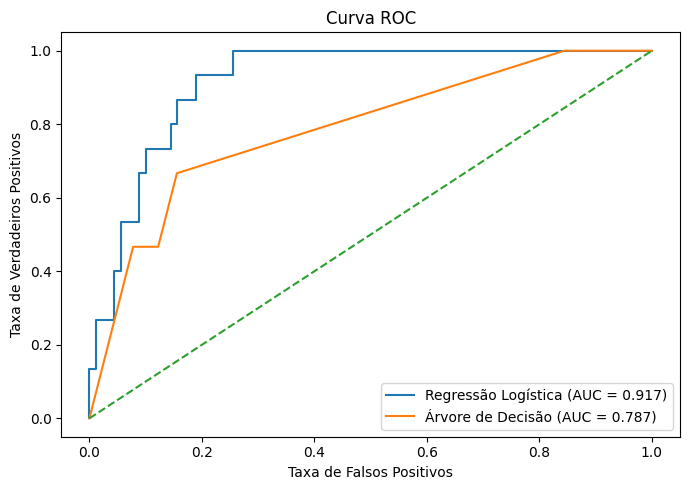

In [110]:
# Complete aqui
fpr_log, tpr_log, _ = roc_curve(y_test, proba_log)
fpr_tree, tpr_tree, _ = roc_curve(y_test, proba_tree)

plt.figure(figsize=(7,5))
plt.plot(fpr_log, tpr_log, label=f'Regressão Logística (AUC = {roc_auc_score(y_test, proba_log):.3f})')
plt.plot(fpr_tree, tpr_tree, label=f'Árvore de Decisão (AUC = {roc_auc_score(y_test, proba_tree):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend()
plt.tight_layout()
plt.show()

### `predict_proba()[:, 1]` e `predict_proba()[:, 0]`

O `predict_proba()` retorna a probabilidade de cada registro pertencer a cada classe.

Em um problema de classificação binária:

- `[:, 1]` → retorna a probabilidade da **classe 1 (Falha)**.
- `[:, 0]` → retorna a probabilidade da **classe 0 (Não Falha)**.

Como existem apenas duas classes, as probabilidades são complementares:

**P(Não Falha) = 1 − P(Falha)**

Por isso, normalmente utilizamos `[:, 1]` para calcular a curva ROC, considerando a **classe 1 como classe positiva**.

Se quisermos analisar a ROC considerando a **classe 0 como positiva**, devemos utilizar `[:, 0]` e também inverter o `y_test`:

```python
y_test_invertido = 1 - y_test
```

Dessa forma, a classe que originalmente era `0` passa a ser representada por `1`, mantendo a correspondência entre o valor real e a probabilidade utilizada na curva ROC.

### Aplique aqui o calculo ROC pra a classe 0(Não falha) considerando a explicação acima

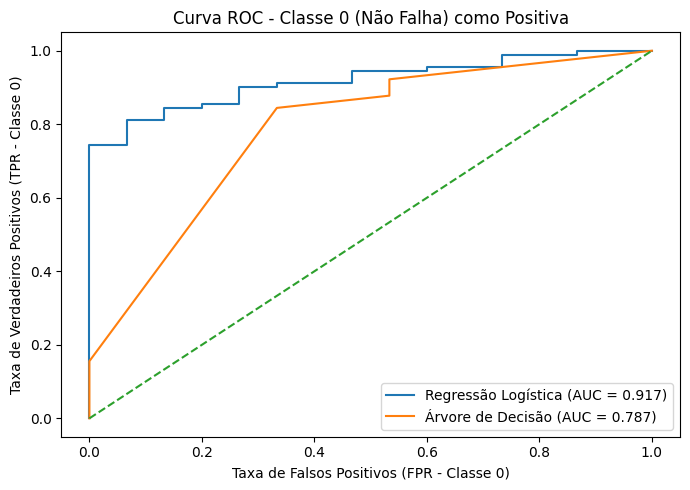

In [111]:
# Complete aqui o grafico de ROC para predict_proba()[:,0] O exerciio visa fixar o conceito de ROC e de como o modelo consegue separar as classes

y_test_inv = 1 - y_test
proba_log_0 = modelo_logistico.predict_proba(X_test)[:, 0]
proba_tree_0 = modelo_arvore.predict_proba(X_test)[:, 0]

fpr_log_0, tpr_log_0, _ = roc_curve(y_test_inv, proba_log_0)
fpr_tree_0, tpr_tree_0, _ = roc_curve(y_test_inv, proba_tree_0)

plt.figure(figsize=(7,5))
plt.plot(fpr_log_0, tpr_log_0, label=f'Regressão Logística (AUC = {roc_auc_score(y_test_inv, proba_log_0):.3f})')
plt.plot(fpr_tree_0, tpr_tree_0, label=f'Árvore de Decisão (AUC = {roc_auc_score(y_test_inv, proba_tree_0):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('Taxa de Falsos Positivos (FPR - Classe 0)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR - Classe 0)')
plt.title('Curva ROC - Classe 0 (Não Falha) como Positiva')
plt.legend()
plt.tight_layout()
plt.show()

###***ROC - Regressão Logisitica***

O gráfico possui limites de 0 a 1 nos dois eixos, portanto o espaço total é 1 × 1 = 1
* A linha diagonal representa o classificador aleatório, com AUC = 0,5.

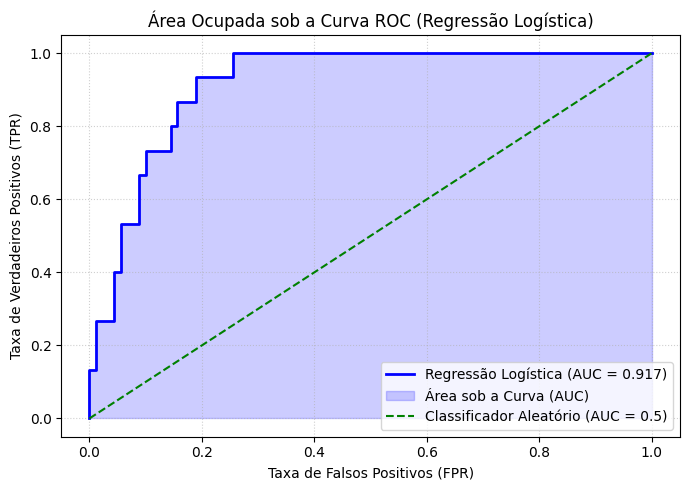

In [112]:
# Como o arquivo de imagem não existe localmente, vamos construir a visualização da área sob a curva diretamente com Matplotlib
import numpy as np
import matplotlib.pyplot as plt

# Recriando a visualização gráfica da curva ROC destacando a área sob a curva (AUC) para a Regressão Logística
plt.figure(figsize=(7, 5))

# Plota a curva ROC da Regressão Logística
plt.plot(fpr_log, tpr_log, color='blue', label=f'Regressão Logística (AUC = {roc_auc_score(y_test, proba_log):.3f})', lw=2)

# Preenche a área sob a curva para ilustrar visualmente o conceito de AUC
plt.fill_between(fpr_log, tpr_log, color='blue', alpha=0.2, label='Área sob a Curva (AUC)')

# Linha guia do classificador aleatório
plt.plot([0, 1], [0, 1], linestyle='--', color='green', label='Classificador Aleatório (AUC = 0.5)')

plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Área Ocupada sob a Curva ROC (Regressão Logística)')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

###***ROC - Arvore de Decisão***

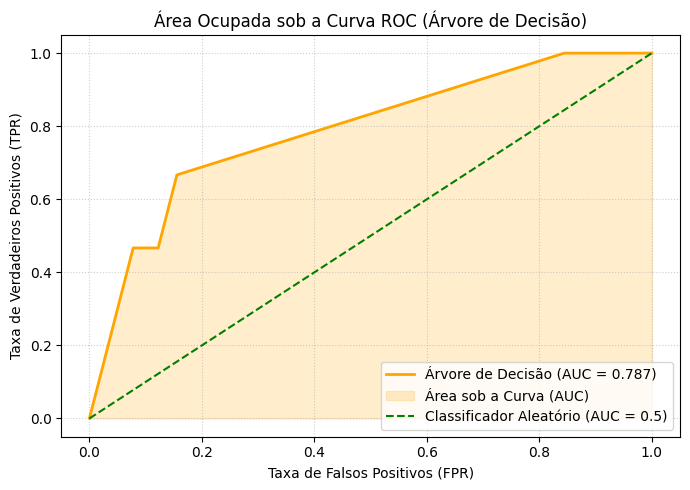

In [113]:
# Como o arquivo de imagem não existe localmente, vamos construir a visualização da área sob a curva diretamente com Matplotlib
import numpy as np
import matplotlib.pyplot as plt

# Recriando a visualização gráfica da curva ROC destacando a área sob a curva (AUC) para a Árvore de Decisão
plt.figure(figsize=(7, 5))

# Plota a curva ROC da Árvore de Decisão
plt.plot(fpr_tree, tpr_tree, color='orange', label=f'Árvore de Decisão (AUC = {roc_auc_score(y_test, proba_tree):.3f})', lw=2)

# Preenche a área sob a curva para ilustrar visualmente o conceito de AUC
plt.fill_between(fpr_tree, tpr_tree, color='orange', alpha=0.2, label='Área sob a Curva (AUC)')

# Linha guia do classificador aleatório
plt.plot([0, 1], [0, 1], linestyle='--', color='green', label='Classificador Aleatório (AUC = 0.5)')

plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Área Ocupada sob a Curva ROC (Árvore de Decisão)')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

> Este gráfico compara dois modelos de classificação usando a curva ROC. No eixo X temos a taxa de falsos positivos e no eixo Y a taxa de verdadeiros positivos. A curva mostra o comportamento do modelo considerando diferentes thresholds. Quanto mais a curva se aproxima do canto superior esquerdo, melhor é a capacidade de separar as classes.

---

***Eixo Y — TPR***<br/>
Vai de 0 a 1:
* 0 = 0% dos positivos reais foram encontrados
* 1 = 100% dos positivos reais foram encontrados

***Eixo X — FPR*** <br/>
Também vai de 0 a 1:
* 0 = 0% dos negativos foram classificados incorretamente como positivos
* 1 = 100% dos negativos foram classificados incorretamente como positivos

>"Como o gráfico vai de 0 a 1 nos dois eixos, a área total é 1. Portanto, uma AUC de 0,917 corresponde a 91,7% dessa área."

#***Linha Verde***
>“A linha verde representa o desempenho esperado de um classificador que não consegue distinguir as duas classes. Ela serve como referência para avaliar as outras curvas.”

>***Obs:*** E uma observação importante: não significa que o modelo verde esteja fazendo 50% de acertos. AUC = 0,5 representa ausência de capacidade de discriminação, não necessariamente uma acurácia de exatamente 50%.

#***Linha Amarela***
Responda:

#***Linha Azul***
Responda:

## 16. Acurácia em bases desbalanceadas

Monte um baseline que prevê sempre a classe majoritária e compare suas métricas com as dos modelos treinados.


In [114]:
# Identificar a classe majoritária em y_test usando o método .mode().
# .mode() retorna a classe que aparece com maior frequência.
# Usar [0] para selecionar o primeiro valor retornado pelo método .mode().
# Armazenar a classe majoritária na variável classe_majoritaria.

# Criar as previsões do modelo baseline usando np.full_like().
# Usar y_test como referência para criar um conjunto de valores com o mesmo tamanho e tipo.
# Usar fill_value=classe_majoritaria para preencher todos os registros
# com a classe majoritária.
# Armazenar essas previsões na variável baseline_pred.
# O baseline sempre fará a mesma previsão: a classe que aparece mais vezes em y_test.

# Calcular a acurácia do baseline usando accuracy_score().
# Comparar os valores reais de y_test com as previsões armazenadas em baseline_pred.
# Armazenar o resultado na variável baseline_acc.

# Calcular o recall do baseline usando recall_score().
# Usar y_test como valores reais e baseline_pred como valores previstos.
# Usar zero_division=0 para retornar 0 caso o cálculo não possa ser realizado.
# Armazenar o resultado na variável baseline_rec.

# Calcular a precisão do baseline usando precision_score().
# Usar y_test como valores reais e baseline_pred como valores previstos.
# Usar zero_division=0 para evitar erro quando não houver previsões positivas.
# Armazenar o resultado na variável baseline_pre.

# Calcular o F1-score do baseline usando f1_score().
# Usar y_test como valores reais e baseline_pred como valores previstos.
# Usar zero_division=0 para evitar erro quando não houver previsões positivas.
# Armazenar o resultado na variável baseline_f1.

# Criar um DataFrame usando pd.DataFrame() para apresentar as métricas do baseline.

# Criar a coluna 'Modelo' e informar o texto 'Baseline classe majoritária'.
# Essa coluna identifica o método que será utilizado como referência.

# Criar a coluna 'Acurácia' usando o valor armazenado em baseline_acc.
# Criar a coluna 'Precisão' usando o valor armazenado em baseline_pre.
# Criar a coluna 'Recall' usando o valor armazenado em baseline_rec.
# Criar a coluna 'F1-score' usando o valor armazenado em baseline_f1.

# Usar o método .round(4) para arredondar todas as métricas para 4 casas decimais.

# Exibir o DataFrame final para comparar o desempenho do baseline
# com os modelos de classificação.

In [115]:
# Complete aqui
classe_majoritaria = y_test.mode()[0]
baseline_pred = np.full_like(y_test, fill_value=classe_majoritaria)

baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_rec = recall_score(y_test, baseline_pred, zero_division=0)
baseline_pre = precision_score(y_test, baseline_pred, zero_division=0)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

pd.DataFrame({
    'Modelo': ['Baseline classe majoritária'],
    'Acurácia': [baseline_acc],
    'Precisão': [baseline_pre],
    'Recall': [baseline_rec],
    'F1-score': [baseline_f1]
}).round(4)

,Modelo,Acurácia,Precisão,Recall,F1-score
0,Baseline classe majoritária,0.8571,0.0,0.0,0.0


| Métrica  |  Resultado | Explicação                          |
| -------- | ---------: | ----------------------------------- |
| Acurácia | **85,71%** | Acertou os casos que eram 0         |
| Precisão |      **0** | Não fez nenhuma previsão 1          |
| Recall   |      **0** | Não encontrou nenhum caso 1         |
| F1       |      **0** | Não houve identificação da classe 1 |


>“O baseline simplesmente escolheu a classe 0 para todos os registros. Como a classe 0 é majoritária, ele conseguiu uma acurácia de 85,71%. Porém, como nunca previu a classe 1, não conseguiu identificar nenhum caso positivo, resultando em Recall e F1 iguais a zero.”

>“Embora o baseline tenha 85,71%, sozinho, não significa que temos um bom classificador

## 17. Interpretação orientada

Escreva:
- qual modelo detecta melhor as falhas;
- qual modelo parece mais equilibrado;
- qual métrica parece mais importante para este problema industrial.


**Resposta do aluno:**  
- Melhor para detectar falhas:  
- Modelo mais equilibrado:  
- Métrica mais importante:  


## 18. Síntese sobre bases desbalanceadas

Explique, com suas palavras, por que a acurácia isolada pode ser insuficiente em bases desbalanceadas.


**Resposta do aluno:**  


## 19. Exportação dos resultados

Salve:
- a tabela de métricas;
- a matriz de confusão da regressão logística;
- a matriz de confusão da árvore.


In [116]:
# Salvando a tabela de métricas e as matrizes de confusão em arquivos CSV
metricas.to_csv('metricas_modelos.csv', index=False)

pd.DataFrame(cm_log, columns=['Pred_0', 'Pred_1'], index=['Real_0', 'Real_1']).to_csv(
    'matriz_confusao_logistica.csv'
)
pd.DataFrame(cm_tree, columns=['Pred_0', 'Pred_1'], index=['Real_0', 'Real_1']).to_csv(
    'matriz_confusao_arvore.csv'
)

print('Arquivos exportados com sucesso.')

Arquivos exportados com sucesso.


## 20. Fechamento

Verifique se você:
- calculou corretamente as métricas de classificação;
- interpretou a matriz de confusão com coerência;
- justificou a métrica mais adequada ao problema;
- analisou criticamente o desbalanceamento da base.
